# Интерпретация Logistic Regression

В предыдущих экспериментах лучший AP показала Logistic Regression с One-Hot Encoding. Теперь проверим, какие признаки влияют на её предсказания и насколько модель от них зависит.

## 1. Коэффициенты Logistic Regression

Коэффициенты показывают связь признаков с прогнозом модели. Положительный коэффициент увеличивает логарифм шансов положительного класса, отрицательный — уменьшает.

Числовые признаки масштабированы, а категориальные преобразованы через One-Hot Encoding, поэтому сравнивать все коэффициенты напрямую не совсем корректно.


In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance

project_root = Path.cwd().resolve()

if project_root.name == 'notebooks':
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

model = joblib.load(
    project_root / 'models' / 'logistic_onehot.joblib'
)

print('Шаги пайплайна:', list(model.named_steps))
print('Классы:', model.classes_)


Шаги пайплайна: ['preprocessing', 'model']
Классы: [0 1]


In [2]:
# Предобработка
preprocessing = model.named_steps['preprocessing']

# Названия признаков после преобразования
feature_names = (
    preprocessing
    .named_steps['columns']
    .get_feature_names_out()
)

# Коэффициенты обученной модели
coefficients = model.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['Abs coefficient'] = (
    coef_df['Coefficient'].abs()
)

# Проверяем количество признаков
assert len(feature_names) == len(coefficients)

print('Количество признаков:', len(coef_df))

display(
    coef_df.sort_values(
        'Abs coefficient',
        ascending=False
    ).head(20)
)


Количество признаков: 63


,Feature,Coefficient,Abs coefficient
3,numeric__emp_var_rate,-2.498205,2.498205
57,onehot__month_mar,1.338341,1.338341
4,numeric__cons_price_idx,1.266246,1.266246
62,binary__pdays_known,1.012759,1.012759
56,onehot__month_jun,-0.839513,0.839513
23,onehot__contact_telephone,-0.679063,0.679063
29,onehot__poutcome_failure,-0.645090,0.645090
59,onehot__month_nov,-0.600189,0.600189
58,onehot__month_may,-0.553032,0.553032
7,numeric__nr_employed,0.512783,0.512783


### 1.1. Визуализация коэффициентов

Рассмотрим десять наибольших положительных и десять наименьших отрицательных коэффициентов.

График показывает направление и величину коэффициентов, но не позволяет напрямую оценить важность исходных признаков. Числовые признаки масштабированы, категориальные закодированы через One-Hot Encoding, а часть признаков коррелирует между собой.


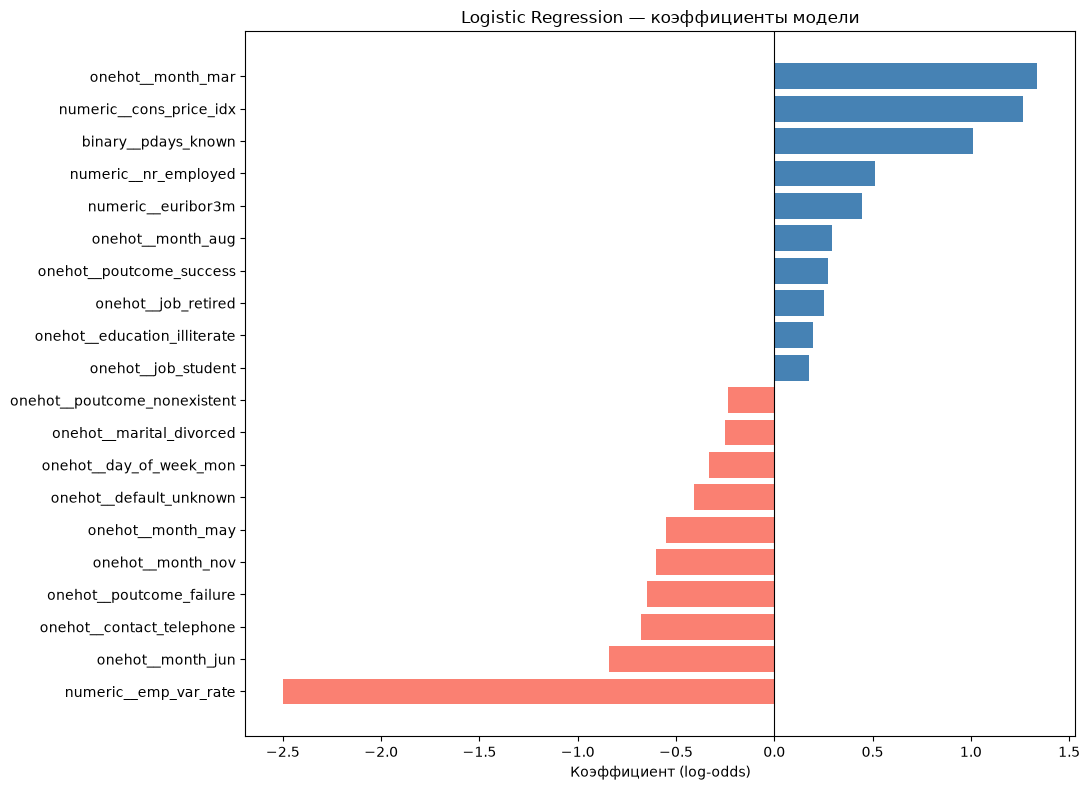

In [3]:
# 10 наибольших положительных коэффициентов
top_positive = coef_df.nlargest(
    10, 'Coefficient'
)

# 10 наименьших отрицательных коэффициентов
top_negative = coef_df.nsmallest(
    10, 'Coefficient'
)

# Объединяем и сортируем для графика
top_coef = pd.concat([
    top_negative,
    top_positive
]).sort_values('Coefficient')

fig, ax = plt.subplots(figsize=(11, 8))

colors = np.where(
    top_coef['Coefficient'] > 0,
    'steelblue',
    'salmon'
)

ax.barh(
    top_coef['Feature'],
    top_coef['Coefficient'],
    color=colors
)

ax.axvline(0, color='black', linewidth=0.8)

ax.set_title('Logistic Regression — коэффициенты модели')
ax.set_xlabel('Коэффициент (log-odds)')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

## 2. Permutation Importance

Оценим, насколько снижается Average Precision при случайном перемешивании каждого исходного признака.

Для проверки выделим валидационную часть из Train и обучим на оставшихся данных копию выбранной Logistic Regression. Тестовую выборку использовать не будем.


In [4]:
# Загружаем данные
df = pd.read_csv(
    project_root / 'data' / 'raw' / 'banking.csv'
)

X = df.drop(columns=['y', 'duration'])
y = df['y']

# Воспроизводим исходное разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Выделяем валидационную часть внутри Train
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Копия пайплайна с теми же гиперпараметрами
interpret_model = clone(model)
interpret_model.fit(X_fit, y_fit)

val_scores = interpret_model.predict_proba(X_val)[:, 1]

print('Размер валидационной выборки:', len(X_val))
print('Validation AP:', round(
    average_precision_score(y_val, val_scores), 4
))


Размер валидационной выборки: 6590
Validation AP: 0.4473


In [5]:
result = permutation_importance(
    interpret_model,
    X_val,
    y_val,
    scoring='average_precision',
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'AP decrease': result.importances_mean,
    'Std': result.importances_std
})

importance_df = importance_df.sort_values(
    'AP decrease',
    ascending=False
)

display(importance_df.round(4))


,Feature,AP decrease,Std
14,emp_var_rate,0.3524,0.0019
15,cons_price_idx,0.1499,0.0046
8,month,0.0495,0.0047
11,pdays,0.0307,0.0022
7,contact,0.0240,0.0023
18,nr_employed,0.0184,0.0069
13,poutcome,0.0142,0.0012
17,euribor3m,0.0139,0.0048
16,cons_conf_idx,0.0086,0.0023
9,day_of_week,0.0075,0.0019


### 2.1. Визуализация важности признаков

Покажем признаки, перемешивание которых сильнее всего снижает Average Precision модели.


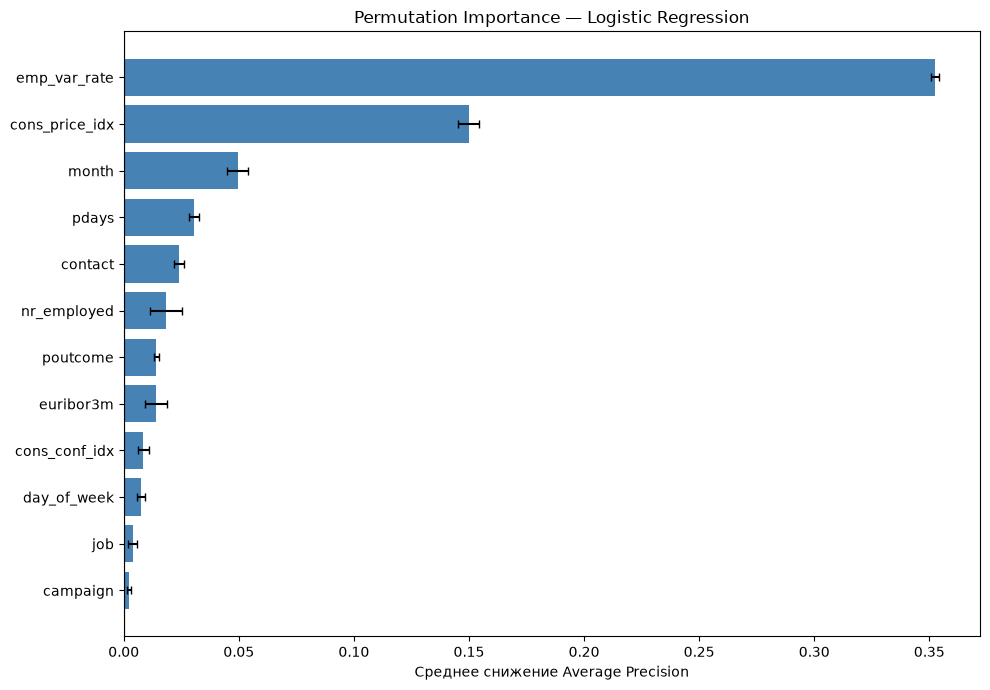

In [6]:
# 12 признаков с наибольшим снижением AP
top_importance = (
    importance_df
    .head(12)
    .sort_values('AP decrease')
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_importance['Feature'],
    top_importance['AP decrease'],
    xerr=top_importance['Std'],
    color='steelblue',
    capsize=3
)

ax.axvline(0, color='black', linewidth=0.8)

ax.set_title('Permutation Importance — Logistic Regression')
ax.set_xlabel('Среднее снижение Average Precision')
ax.set_ylabel('')

plt.tight_layout()
plt.show()


## 3. Групповая важность экономических признаков

Экономические показатели в датасете сильно коррелируют между собой. При оценке Permutation Importance по отдельным признакам это может влиять на результаты.

Проверим, насколько изменится Average Precision, если одновременно перемешать все пять экономических показателей. Для этого будем переставлять целые строки экономических признаков, сохраняя зависимости между ними.


In [7]:
# Экономические признаки
economic_cols = [
    'emp_var_rate',
    'cons_price_idx',
    'cons_conf_idx',
    'euribor3m',
    'nr_employed'
]

rng = np.random.default_rng(42)

# Исходное качество на Validation
baseline_ap = average_precision_score(
    y_val,
    interpret_model.predict_proba(X_val)[:, 1]
)

group_ap = []

# Повторяем перемешивание 10 раз
for _ in range(10):
    X_permuted = X_val.copy()

    shuffled_idx = rng.permutation(len(X_val))

    # Все экономические признаки перемешиваем
    # одинаковым образом, сохраняя их взаимосвязи
    X_permuted[economic_cols] = (
        X_val[economic_cols]
        .iloc[shuffled_idx]
        .to_numpy()
    )

    y_score = interpret_model.predict_proba(
        X_permuted
    )[:, 1]

    group_ap.append(
        average_precision_score(y_val, y_score)
    )

group_ap = np.array(group_ap)
ap_decrease = baseline_ap - group_ap

print('Исходный AP:', round(baseline_ap, 4))
print('AP после перемешивания:', round(group_ap.mean(), 4))
print('Среднее снижение AP:', round(ap_decrease.mean(), 4))
print('Стандартное отклонение:', round(ap_decrease.std(), 4))


Исходный AP: 0.4473
AP после перемешивания: 0.2116
Среднее снижение AP: 0.2357
Стандартное отклонение: 0.0098


### Выводы

После одновременного перемешивания пяти экономических признаков AP снизилась с 0.4473 до 0.2116. Среднее снижение составило 0.2357.

При отдельном перемешивании `emp_var_rate` снижение оказалось ещё больше — 0.3524. Это может объясняться тем, что одиночное перемешивание нарушает взаимосвязи между экономическими показателями, а групповое сохраняет их.

Результаты показывают, что модель сильно зависит от экономических данных. Однако по этому эксперименту нельзя определить, насколько ухудшится качество, если полностью исключить эти признаки и обучить модель заново.


## 4. Итоги

Анализ коэффициентов и Permutation Importance показал, что Logistic Regression в первую очередь опирается на экономические показатели. Среди них особенно выделяются `emp_var_rate` и `cons_price_idx`.

Также для прогнозирования имеют значение месяц контакта, история предыдущих обращений и способ связи с клиентом. Личные характеристики, такие как возраст, профессия и образование, оказались менее важными в данном эксперименте.

Результаты в целом согласуются с EDA, однако интерпретацию отдельных экономических показателей осложняет их высокая корреляция.

Следующим шагом стоит проверить, как изменится качество модели при исключении части экономических признаков.


### Ограничения

Permutation Importance рассчитывалась на валидационной части Train для копии модели, обученной на остальных данных. Тестовая выборка в этом эксперименте не использовалась, но гиперпараметры ранее подбирались на всём Train.

Из-за корреляции признаков их важность может оцениваться неточно. Полученные результаты показывают, на какую информацию опирается модель, но не доказывают причинного влияния признаков на отклик клиента.
